# Crime Data Recommendation System

## Data Processing

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Load data
csv_path = Path("data/chicago_crimes.csv")
if csv_path.exists():
    df = pd.read_csv(csv_path)
else:
    url = "https://data.cityofchicago.org/resource/ijzp-q8t2.csv?$limit=1000000"
    df = pd.read_csv(url)
    csv_path.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(csv_path, index=False)

# Only include the following crimes
crime_types = [
    "ROBBERY",
    "THEFT",
    "MOTOR VEHICLE THEFT",
    "BURGLARY",
    "CRIMINAL DAMAGE",
    "CRIMINAL TRESPASS",
]
df = df.loc[df["primary_type"].isin(crime_types)].copy()
print(f"Matching crime rows: {len(df):,}")

# Drop un-needed features

Matching crime rows: 516,056


## EDA - Exploratory Data Analysis

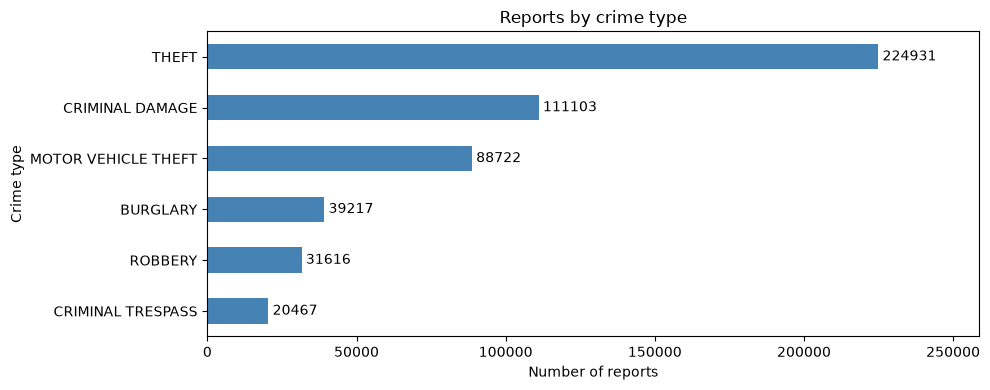

In [2]:
# Distribution of crime types
crime_counts = df["primary_type"].value_counts().sort_values()
ax = crime_counts.plot.barh(figsize=(10, 4), color="steelblue")
ax.set(title="Reports by crime type", xlabel="Number of reports", ylabel="Crime type")
ax.bar_label(ax.containers[0], padding=3)
ax.margins(x=0.15)
plt.tight_layout()
plt.show()

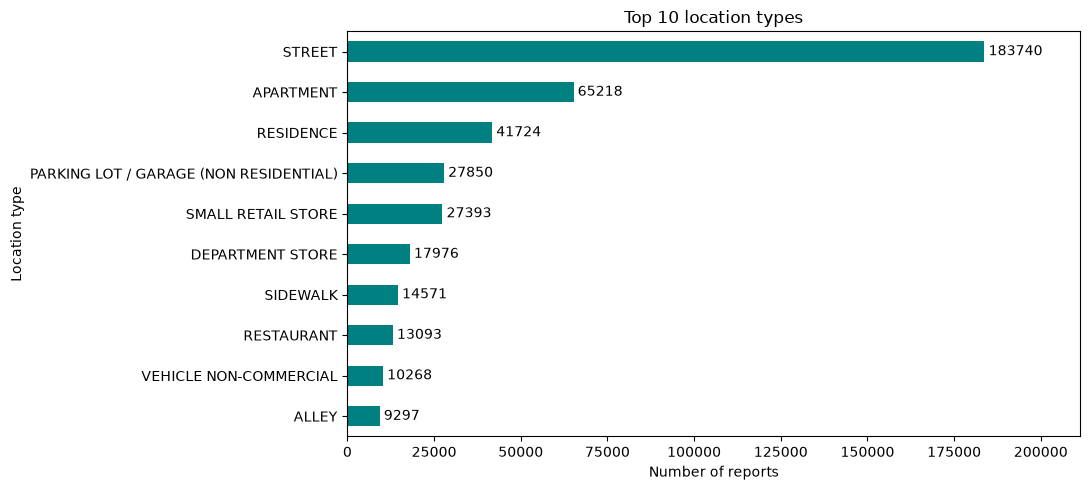

In [3]:
# Distribution of locations
top_locations = df["location_description"].value_counts().head(10).sort_values()
ax = top_locations.plot.barh(figsize=(11, 5), color="teal")
ax.set(title="Top 10 location types", xlabel="Number of reports", ylabel="Location type")
ax.bar_label(ax.containers[0], padding=3)
ax.margins(x=0.15)
plt.tight_layout()
plt.show()

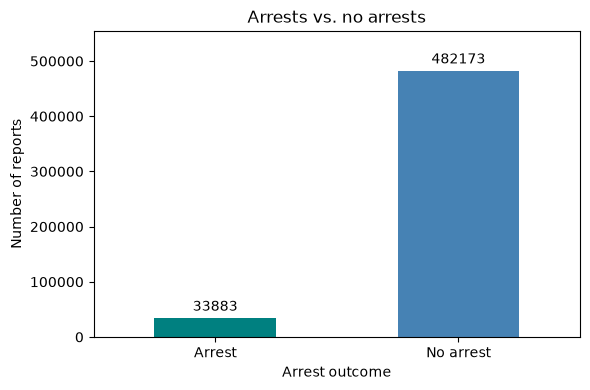

In [4]:
arrest_counts = df["arrest"].value_counts().reindex([True, False], fill_value=0)
arrest_counts.index = ["Arrest", "No arrest"]
ax = arrest_counts.plot.bar(figsize=(6, 4), color=["teal", "steelblue"], rot=0)
ax.set(title="Arrests vs. no arrests", xlabel="Arrest outcome", ylabel="Number of reports")
ax.bar_label(ax.containers[0], padding=3)
ax.margins(y=0.15)
plt.tight_layout()
plt.show()

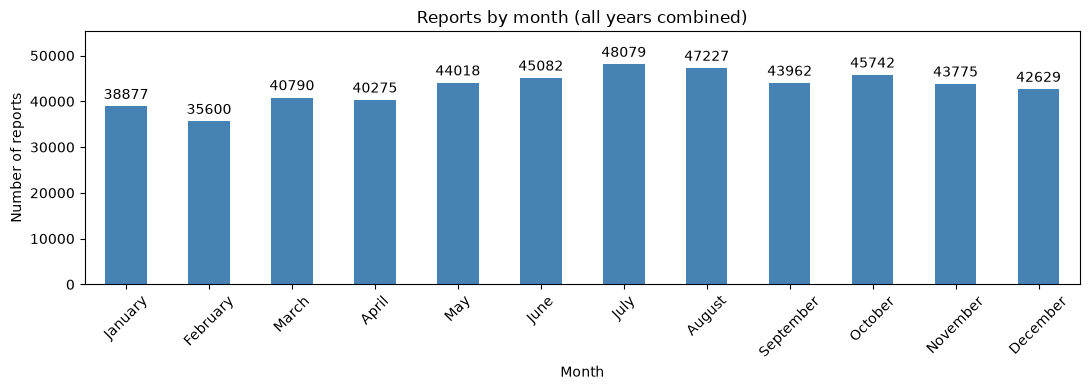

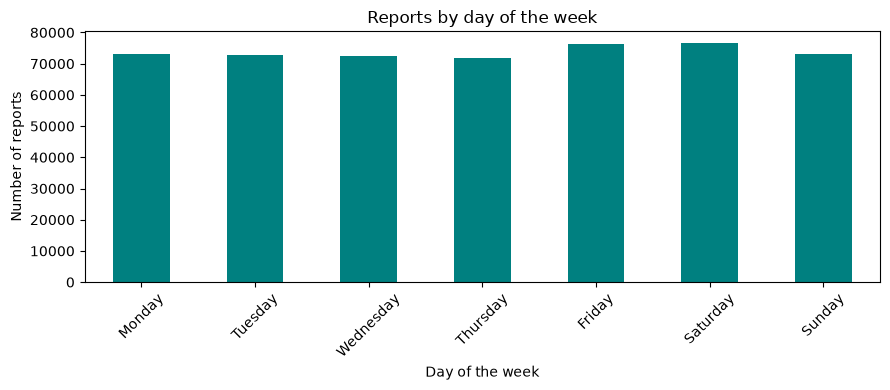

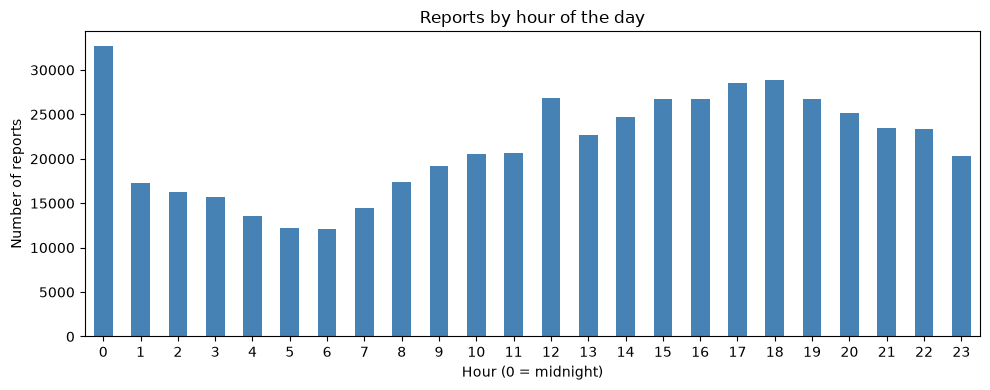

In [5]:
crime_dates = pd.to_datetime(df["date"], errors="coerce")
months = [
    "January", "February", "March", "April", "May", "June",
    "July", "August", "September", "October", "November", "December",
]
monthly_counts = crime_dates.dt.month_name().value_counts().reindex(months, fill_value=0)

ax = monthly_counts.plot.bar(figsize=(11, 4), color="steelblue", rot=45)
ax.set(title="Reports by month (all years combined)", xlabel="Month", ylabel="Number of reports")
ax.bar_label(ax.containers[0], padding=3)
ax.margins(y=0.15)
plt.tight_layout()
plt.show()


weekdays = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_counts = crime_dates.dt.day_name().value_counts().reindex(weekdays, fill_value=0)
ax = weekday_counts.plot.bar(figsize=(9, 4), color="teal", rot=45)
ax.set(title="Reports by day of the week", xlabel="Day of the week", ylabel="Number of reports")
plt.tight_layout()
plt.show()


hourly_counts = crime_dates.dt.hour.value_counts().reindex(range(24), fill_value=0)
ax = hourly_counts.plot.bar(figsize=(10, 4), color="steelblue", rot=0)
ax.set(title="Reports by hour of the day", xlabel="Hour (0 = midnight)", ylabel="Number of reports")
plt.tight_layout()
plt.show()

# Modeling

### Model 1 - Arrest Made (Logistic Regression)

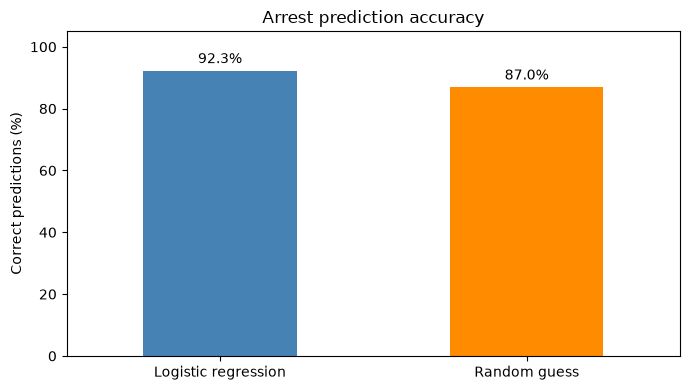

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder

# Use the crime type and location as inputs.
dates = pd.to_datetime(df["date"])
features = df[["primary_type", "location_description", "community_area"]].astype(str)

# Train on the older 80% of reports and test on the newer 20%.
split_date = dates.quantile(0.8)
training_rows = dates < split_date
testing_rows = ~training_rows

# Convert category names into numeric input columns.
encoder = OneHotEncoder(handle_unknown="ignore")
X_train = encoder.fit_transform(features.loc[training_rows])
X_test = encoder.transform(features.loc[testing_rows])

# Use 1 for an arrest and 0 for no arrest.
y_train = df.loc[training_rows, "arrest"].astype(int).to_numpy()
y_test = df.loc[testing_rows, "arrest"].astype(int).to_numpy()

# Fit the model and predict arrests for the test reports.
arrest_model = LogisticRegression(max_iter=1000)
arrest_model.fit(X_train, y_train)
arrest_predictions = arrest_model.predict(X_test)

# Randomly guess "arrest" at the rate seen in the training data.
arrest_rate = y_train.mean()
rng = np.random.default_rng(42)
random_predictions = rng.random(len(y_test)) < arrest_rate

# Compare the percentage of correct predictions.
accuracy = pd.Series({
    "Logistic regression": (arrest_predictions == y_test).mean() * 100,
    "Random guess": (random_predictions == y_test).mean() * 100,
})

ax = accuracy.plot.bar(figsize=(7, 4), rot=0, color=["steelblue", "darkorange"])
ax.set(title="Arrest prediction accuracy", ylabel="Correct predictions (%)", ylim=(0, 105))
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
plt.tight_layout()
plt.show()

# Expose uniquely-named handles for Model 4 (Model 3 reuses the `encoder` name).
m1_model, m1_encoder = arrest_model, encoder


### Model 2 - Location (Spatial Ridge Regression + Latent Factor Model)

For Model 2, we predict where crimes happen across Chicago's 77 community areas (`1` to `77`) so Model 4 can combine spatial crime volume with the arrest probabilities from Models 1 and 3.

- **Part 2A (Monthly Spatial Ridge):** Evaluates a retrospective rolling forecast on the 10 complete calendar months from Jan to Oct 2026, predicting each month using counts from earlier months (training targets Dec 2023 to Apr 2025, validation May to Dec 2025, with Dec 2022 to Nov 2023 used only for lag warm up).
- **Part 2B (Shift Latent Factor Model):** Uses the exact same 80/20 datetime cutoff as Models 1 and 3 (`2026-01-05 16:28` through `2026-11-18`) over valid community areas to model how hotspots change across crime types, 4 hour time slots, and weekday vs. weekend.

For ranking metrics, true hotspots in each slice are areas at or above the 10th highest positive count (including ties). `Top 5 hit (%)` is the share of our top 5 picks inside those true hotspots, `Capture@10 (%)` is the share of slice crimes inside our top 10 picks (averaged equally across slices), and `AUC` (Area Under the Curve) is the probability a true hotspot ranks above a quieter area (`0.50` is random).


Rolling monthly forecast on test (2026-01 to 2026-10, 4,620 cells; slice max Capture@10 = 39.6%):
Validation RMSE (log): lags only = 0.4122, Spatial Ridge = 0.4033 (alpha=1)
                       R2 (log)  Count RMSE  R2 (cnt)  Top 5 hit (%)  Capture@10 (%)    AUC
Model                                                                                      
Random guess                n/a         n/a       n/a         13.560          13.026  0.503
Overall average          -0.004      34.736    -0.090            n/a             n/a    n/a
Past area average         0.812      10.320     0.904         92.333          37.491  0.960
Last 3 months average     0.853       8.562     0.934         95.333          37.252  0.964
Ridge (lags only)         0.873       7.680     0.947         96.000          37.745  0.969
Spatial Ridge (a=1)       0.879       7.618     0.948         95.667          37.639  0.968


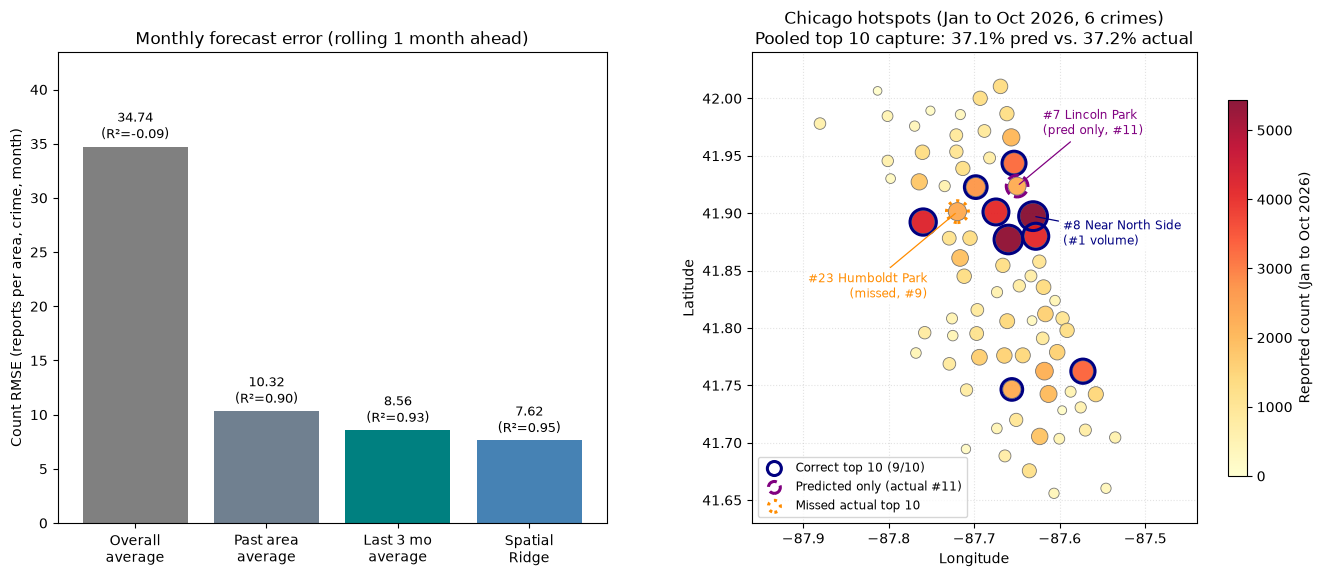

In [7]:
from scipy.stats import rankdata
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Ridge
from sklearn.preprocessing import OneHotEncoder, StandardScaler

AREAS = list(range(1, 78))
CRIME_TYPES = [
    "ROBBERY", "THEFT", "MOTOR VEHICLE THEFT",
    "BURGLARY", "CRIMINAL DAMAGE", "CRIMINAL TRESPASS",
]
CA_NAMES = {
    6: "Lake View", 7: "Lincoln Park", 8: "Near North Side",
    23: "Humboldt Park", 25: "Austin", 28: "Near West Side", 32: "The Loop",
}


def eval_location(y_true, y_pred, counts, groups, inc_reg=True, inc_rank=True, n_rand=1):
    yt, yp = np.asarray(y_true, float), np.asarray(y_pred, float)
    if inc_reg:
        ct, cp = np.expm1(yt), np.maximum(0.0, np.expm1(yp))
        r2_log = float(1.0 - np.mean((yt - yp) ** 2) / np.var(yt))
        rmse_cnt = float(np.sqrt(np.mean((ct - cp) ** 2)))
        r2_cnt = float(1.0 - np.mean((ct - cp) ** 2) / np.var(ct))
    else:
        r2_log, rmse_cnt, r2_cnt = np.nan, np.nan, np.nan

    rng = np.random.default_rng(42)
    hit5, cap10, aucs, oracle10 = [], [], [], []
    for _, g in pd.DataFrame({"grp": groups, "c": counts, "s": yp}).groupby("grp", sort=False):
        c = g["c"].to_numpy(float)
        if c.sum() <= 0:
            continue
        top_vals = np.sort(c)[::-1]
        is_hot = (c >= top_vals[min(10, int((c > 0).sum())) - 1]) & (c > 0)
        n_pos, n_neg = int(is_hot.sum()), len(c) - int(is_hot.sum())
        oracle10.append(top_vals[:10].sum() / c.sum())
        if not inc_rank:
            continue

        # Average over random draws for the random baseline; otherwise rank directly by score.
        s_base = g["s"].to_numpy(float)
        draws = [rng.random(len(c)) for _ in range(n_rand)] if n_rand > 1 else [s_base]
        hit5.append(np.mean([is_hot[np.argsort(-s)[:5]].mean() for s in draws]))
        cap10.append(np.mean([c[np.argsort(-s)[:10]].sum() / c.sum() for s in draws]))
        if n_pos > 0 and n_neg > 0:
            # Mann Whitney rank sum formula for pairwise AUC (0.5 credit for ties).
            aucs.append(np.mean([
                (rankdata(s, method="average")[is_hot].sum() - n_pos * (n_pos + 1) / 2)
                / (n_pos * n_neg)
                for s in draws
            ]))

    out = {
        "R2 (log)": r2_log, "Count RMSE": rmse_cnt, "R2 (cnt)": r2_cnt,
        "Top 5 hit (%)": float(np.mean(hit5) * 100) if inc_rank else np.nan,
        "Capture@10 (%)": float(np.mean(cap10) * 100) if inc_rank else np.nan,
        "AUC": float(np.mean(aucs)) if inc_rank else np.nan,
    }
    return out, float(np.mean(oracle10) * 100)


# Copy df so Model 3 sees the original table; keep valid Chicago community areas 1..77.
loc_df = df.copy()
loc_df["dt"] = pd.to_datetime(loc_df["date"], errors="coerce")
loc_test_cutoff = loc_df["dt"].quantile(0.8)
loc_val_cutoff = loc_df.loc[loc_df["dt"] < loc_test_cutoff, "dt"].quantile(0.8)
loc_ca = pd.to_numeric(loc_df["community_area"], errors="coerce")
loc_df = loc_df.loc[loc_ca.between(1, 77)].copy()
loc_df["ca"] = loc_ca.loc[loc_ca.between(1, 77)].astype(int)
loc_df["ym"] = loc_df["dt"].dt.to_period("M")
val_start_ym, test_start_ym = loc_val_cutoff.to_period("M"), loc_test_cutoff.to_period("M")

# Keep complete calendar months and build monthly (area, crime_type) counts + past lags.
ym_days = loc_df.groupby("ym")["dt"].apply(lambda s: s.dt.day.nunique())
complete_yms = sorted(p for p, nd in ym_days.items() if nd == p.days_in_month)
panel_idx = pd.MultiIndex.from_product(
    [complete_yms, AREAS, CRIME_TYPES], names=["ym", "ca", "primary_type"]
)
panel = (
    loc_df.loc[loc_df["ym"].isin(complete_yms)]
    .groupby(["ym", "ca", "primary_type"]).size()
    .reindex(panel_idx, fill_value=0).rename("count").reset_index()
    .sort_values(["ca", "primary_type", "ym"]).reset_index(drop=True)
)
panel["y"], panel["month"] = np.log1p(panel["count"]), panel["ym"].dt.month
panel["area_crime"] = panel["ca"].astype(str) + "_" + panel["primary_type"]

grp = panel.groupby(["ca", "primary_type"], sort=False)["y"]
panel["lag_1"], panel["lag_12"] = grp.shift(1), grp.shift(12)
panel["roll_3"] = grp.transform(lambda s: s.shift(1).rolling(3, min_periods=3).mean())

area_tot = panel.groupby(["ym", "ca"], as_index=False)["count"].sum().sort_values(["ca", "ym"])
area_tot["area_total_lag_1"] = area_tot.groupby("ca")["count"].transform(
    lambda s: np.log1p(s).shift(1)
)
panel = panel.merge(area_tot[["ym", "ca", "area_total_lag_1"]], on=["ym", "ca"], how="left")

# Compute area centroids and k=12 Haversine neighbor weights (chosen on validation) from Train.
train_ev = loc_df.loc[loc_df["ym"] < val_start_ym]
spatial = (
    train_ev.dropna(subset=["latitude", "longitude"])
    .groupby("ca")[["latitude", "longitude"]].mean().reindex(AREAS)
    .rename(columns={"latitude": "centroid_lat", "longitude": "centroid_lon"})
)
lat_r = np.radians(spatial["centroid_lat"].to_numpy())[:, None]
lon_r = np.radians(spatial["centroid_lon"].to_numpy())[:, None]
hav = (
    np.sin((lat_r - lat_r.T) / 2) ** 2
    + np.cos(lat_r) * np.cos(lat_r.T) * np.sin((lon_r - lon_r.T) / 2) ** 2
)
dist_km = 2 * 6371.0 * np.arcsin(np.sqrt(np.clip(hav, 0.0, 1.0)))

W = np.zeros((77, 77))
for i in range(77):
    d = dist_km[i].copy()
    d[i] = np.inf
    nb = np.argsort(d)[:12]
    inv_d = 1.0 / np.maximum(d[nb], 0.1)
    W[i, nb] = inv_d / inv_d.sum()

# Compute lagged crime count of neighboring areas using inverse distance weights W.
area_idx = pd.Index(AREAS, name="ca")
nbr_parts = []
for crime in CRIME_TYPES:
    piv = panel.loc[panel["primary_type"] == crime].pivot(
        index="ym", columns="ca", values="lag_1"
    )[AREAS]
    nb_df = pd.DataFrame(piv.to_numpy() @ W.T, index=piv.index, columns=area_idx)
    nb_df = nb_df.stack(future_stack=True).rename("nbr_crime_lag_1").reset_index()
    nb_df["primary_type"] = crime
    nbr_parts.append(nb_df)
nbr_all = pd.concat(nbr_parts, ignore_index=True)
panel = panel.merge(nbr_all, on=["ym", "ca", "primary_type"], how="left")

# Split into train, validation, and test after dropping the 12 month warm up window.
valid_panel = panel.dropna(subset=["lag_12"]).copy()
tr = valid_panel.loc[valid_panel["ym"] < val_start_ym]
va = valid_panel.loc[(valid_panel["ym"] >= val_start_ym) & (valid_panel["ym"] < test_start_ym)]
trva = valid_panel.loc[valid_panel["ym"] < test_start_ym]
te = valid_panel.loc[valid_panel["ym"] >= test_start_ym].copy()
hist_trva = panel.loc[panel["ym"] < test_start_ym]

cat_cols = ["area_crime", "month"]
lag_cols = ["lag_1", "roll_3", "lag_12", "area_total_lag_1"]
num_cols = lag_cols + ["nbr_crime_lag_1"]


def fit_ridge(train_df, eval_df, n_cols, alpha):
    pre = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
        ("num", StandardScaler(), n_cols),
    ])
    model = Ridge(alpha=alpha).fit(
        pre.fit_transform(train_df[cat_cols + n_cols]), train_df["y"].to_numpy()
    )
    return model.predict(pre.transform(eval_df[cat_cols + n_cols]))


# Tune Ridge alpha on validation log RMSE, checking lags alone vs. lags + nearby spillover.
te_keys = te["ym"].astype(str) + "|" + te["primary_type"]
ridge_preds = {}
for name, n_cols in [("Ridge (lags only)", lag_cols), ("Spatial Ridge", num_cols)]:
    best_a, best_val_log = min(
        ((a, float(np.sqrt(np.mean((va["y"] - fit_ridge(tr, va, n_cols, a)) ** 2))))
         for a in [0.1, 1.0, 10.0, 100.0, 1000.0]),
        key=lambda x: x[1],
    )
    ridge_preds[name] = (fit_ridge(trva, te, n_cols, best_a), best_a, best_val_log)

p_ridge_final, loc_ridge_alpha, ridge_val_log = ridge_preds["Spatial Ridge"]
te["pred_cnt"] = np.maximum(0.0, np.expm1(p_ridge_final))

past_area_avg = (
    te.set_index(["ca", "primary_type"]).index
    .map(hist_trva.groupby(["ca", "primary_type"])["y"].mean()).to_numpy()
)
panel_candidates = [
    ("Random guess", np.zeros(len(te)), False, True, 25),
    ("Overall average", np.full(len(te), hist_trva["y"].mean()), True, False, 1),
    ("Past area average", past_area_avg, True, True, 1),
    ("Last 3 months average", te["roll_3"].to_numpy(), True, True, 1),
    ("Ridge (lags only)", ridge_preds["Ridge (lags only)"][0], True, True, 1),
    (f"Spatial Ridge (a={loc_ridge_alpha:g})", p_ridge_final, True, True, 1),
]
panel_rows = []
for name, pred, inc_reg, inc_rank, n_rand in panel_candidates:
    res, oracle_cap10 = eval_location(
        te["y"], pred, te["count"], te_keys, inc_reg, inc_rank, n_rand
    )
    panel_rows.append({"Model": name, **res})

panel_metrics = pd.DataFrame(panel_rows).set_index("Model")
print(
    f"Rolling monthly forecast on test ({te['ym'].min()} to {te['ym'].max()}, "
    f"{len(te):,} cells; slice max Capture@10 = {oracle_cap10:.1f}%):"
)
print(
    f"Validation RMSE (log): lags only = {ridge_preds['Ridge (lags only)'][2]:.4f}, "
    f"Spatial Ridge = {ridge_val_log:.4f} (alpha={loc_ridge_alpha:g})"
)
print(panel_metrics.round(3).to_string(na_rep="n/a"))

# Plot baseline error comparison (left) and Chicago top 10 hotspot map (right).
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.8), gridspec_kw={"width_ratios": [1, 1.15]})
bar_models = [
    "Overall average", "Past area average",
    "Last 3 months average", f"Spatial Ridge (a={loc_ridge_alpha:g})",
]
plot_m = panel_metrics.loc[bar_models]
bars = axes[0].bar(
    ["Overall\naverage", "Past area\naverage", "Last 3 mo\naverage", "Spatial\nRidge"],
    plot_m["Count RMSE"], color=["gray", "slategray", "teal", "steelblue"],
)
axes[0].bar_label(
    bars,
    labels=[f"{e:.2f}\n(R²={r:.2f})" for e, r in zip(plot_m["Count RMSE"], plot_m["R2 (cnt)"])],
    padding=3, fontsize=9,
)
axes[0].set(
    title="Monthly forecast error (rolling 1 month ahead)",
    ylabel="Count RMSE (reports per area, crime, month)",
    ylim=(0, plot_m["Count RMSE"].max() * 1.25),
)

area_map = te.groupby("ca", as_index=False)[["count", "pred_cnt"]].sum().merge(
    spatial.reset_index()[["ca", "centroid_lat", "centroid_lon"]], on="ca"
)
area_map["actual_rank"] = area_map["count"].rank(ascending=False, method="min").astype(int)
top10_act = set(area_map.nlargest(10, "count")["ca"])
top10_prd = set(area_map.nlargest(10, "pred_cnt")["ca"])
hits, pred_only, missed_act = top10_act & top10_prd, top10_prd - top10_act, top10_act - top10_prd
tot_cnt = area_map["count"].sum()
act_cap = area_map.loc[area_map["ca"].isin(top10_act), "count"].sum() / tot_cnt * 100
prd_cap = area_map.loc[area_map["ca"].isin(top10_prd), "count"].sum() / tot_cnt * 100

ax, vmax = axes[1], area_map["count"].max()
sc = ax.scatter(
    area_map["centroid_lon"], area_map["centroid_lat"], c=area_map["count"],
    s=35 + 320 * (area_map["count"] / vmax), cmap="YlOrRd", vmin=0, vmax=vmax,
    alpha=0.9, edgecolors="dimgray", linewidths=0.6, zorder=3,
)
pred_ranks = sorted(int(r) for r in area_map.loc[area_map["ca"].isin(pred_only), "actual_rank"])
rank_note = f"actual #{pred_ranks[0]}" if len(pred_ranks) == 1 else "outside top 10"
ring_groups = [
    (hits, "navy", "-", f"Correct top 10 ({len(hits)}/10)"),
    (pred_only, "purple", "--", f"Predicted only ({rank_note})"),
    (missed_act, "darkorange", ":", "Missed actual top 10"),
]
for ids, color, style, lbl in ring_groups:
    sub = area_map.loc[area_map["ca"].isin(ids)]
    ax.scatter(
        sub["centroid_lon"], sub["centroid_lat"],
        s=35 + 320 * (sub["count"] / vmax) + 75, facecolors="none",
        edgecolors=color, linewidths=2.2, linestyles=style, label=lbl, zorder=4,
    )

# Label the busiest area, the missed hotspot, and the extra predicted area clearly.
top1_id = set(area_map.nlargest(1, "count")["ca"])
for _, row in area_map.loc[area_map["ca"].isin(top1_id | pred_only | missed_act)].iterrows():
    cid, name = int(row["ca"]), CA_NAMES.get(int(row["ca"]), f"Area {int(row['ca'])}")
    if cid in pred_only:
        tag = f"#{cid} {name}\n(pred only, #{int(row['actual_rank'])})"
        color, dx, dy, ha = "purple", 0.03, 0.055, "left"
    elif cid in missed_act:
        tag = f"#{cid} {name}\n(missed, #{int(row['actual_rank'])})"
        color, dx, dy, ha = "darkorange", -0.035, -0.065, "right"
    else:
        tag, color, dx, dy, ha = f"#{cid} {name}\n(#1 volume)", "navy", 0.035, -0.015, "left"
    ax.annotate(
        tag, xy=(row["centroid_lon"], row["centroid_lat"]),
        xytext=(row["centroid_lon"] + dx, row["centroid_lat"] + dy),
        ha=ha, va="center", fontsize=8.5, color=color,
        bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85),
        arrowprops=dict(arrowstyle="-", color=color, lw=0.9), zorder=5,
    )

ax.legend(loc="lower left", fontsize=8.5, markerscale=0.55)
ax.set(
    title=(
        f"Chicago hotspots (Jan to Oct 2026, 6 crimes)\n"
        f"Pooled top 10 capture: {prd_cap:.1f}% pred vs. {act_cap:.1f}% actual"
    ),
    xlabel="Longitude", ylabel="Latitude", xlim=(-87.96, -87.44), ylim=(41.63, 42.04),
)
ax.set_aspect(1.0 / np.cos(np.radians(41.85)))
ax.grid(True, linestyle=":", alpha=0.35)
fig.colorbar(sc, ax=ax, shrink=0.8, label="Reported count (Jan to Oct 2026)")
plt.tight_layout()
plt.show()


**Takeaways from Part 2A:** Ridge minimizes L2 regularized squared error on `log(1 + count)` (used because monthly crime counts are heavily right skewed), with `alpha` and `k = 12` neighbors tuned on the May to Dec 2025 validation set. Against the rolling `Last 3 months average` baseline (which uses the exact same prior counts), Spatial Ridge cuts monthly count RMSE by roughly 11%, while ranking gains over recent history are small (`Top 5 hit` and slice `Capture@10` are already close to the `39.6%` ceiling) because Chicago's busiest neighborhoods stay stable month to month.

Comparing `Ridge (lags only)` with `Spatial Ridge` shows that recent history plus the `area_crime` interaction drives most of the count improvement, while inverse distance neighbor spillover adds a modest further drop in error (`Val log RMSE` `0.4122` to `0.4033`, `Test RMSE` `7.68` to `7.62`). Note that inverting log predictions with `expm1` slightly understates arithmetic sums (~4% below total observed reports, and explains why the log scale `Overall average` has count `R² = -0.09`). On the pooled 10 month map (`37.1%` predicted vs. `37.2%` actual top 10 share), the single miss is a near tie between neighboring ranks.


#### Part 2B: Latent Factor Model by Shift

Here a **shift** `u` is one combination of crime type (6), 4 hour time slot from Model 3 (6), and weekday vs. weekend (2), giving 72 shifts total, and `a` is one of the 77 community areas. Using alternating least squares, we predict `y(u, a) = log(1 + monthly crime rate)` as $\hat{y}(u, a) = \alpha + \beta_u + \beta_a + \gamma_u^\top \gamma_a$ and compare against random guessing, overall average, area + shift bias (`K = 0`), and raw past shift averages.


C:\Users\brend\AppData\Local\Temp\ipykernel_38420\2857485453.py:6: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  wknd_str = (loc_df["dt"].dt.dayofweek >= 5).astype(int).astype(str)


Shift by area test results (72 shifts x 77 areas; val K=8, lambda=1; max Capture@10 = 40.3%):
                        R2 (log)  Top 5 hit (%)  Capture@10 (%)    AUC
Model                                                                 
Random guess                 n/a         13.344          13.012  0.501
Overall average           -0.006            n/a             n/a    n/a
Area + shift bias          0.779         87.222          36.030  0.940
Past shift average         0.853         89.444          36.926  0.950
Latent factor MF (K=8)     0.866         92.500          37.356  0.958


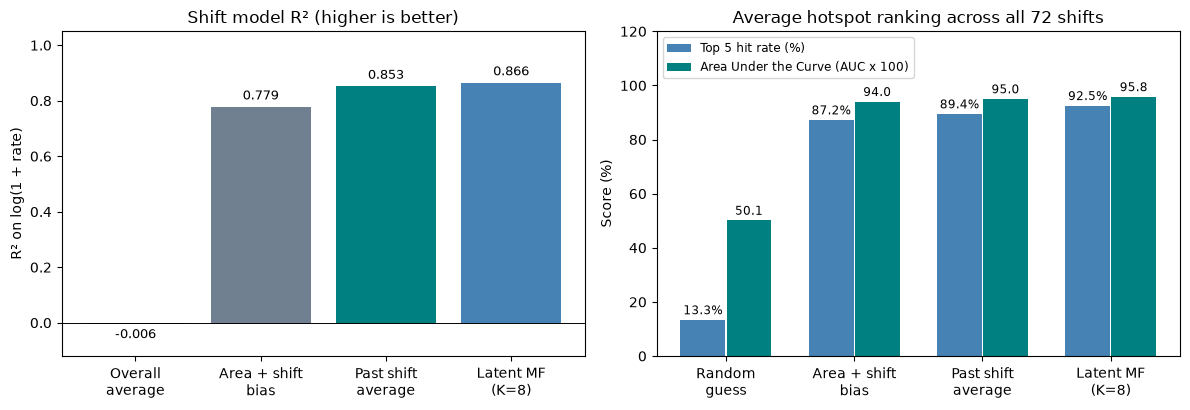


Example Model 4 lookup (forecast_month=2026-10, weekend 00-03 ROBBERY, top 5 of 77):


forecast_month  ca  monthly_pred_cnt       area_name  shift_share  allocated_monthly_crimes  risk_percentile
       2026-10   8             17.81 Near North Side         0.16                      2.91           100.00
       2026-10  25             27.08          Austin         0.07                      1.83            98.70
       2026-10  32             17.34        The Loop         0.10                      1.73            97.40
       2026-10  28             17.94  Near West Side         0.09                      1.61            96.10
       2026-10   6              8.82       Lake View         0.15                      1.30            94.81


In [8]:
# Build 72 shifts x 77 areas monthly rate matrices on the exact 80/20 datetime split.
LOC_SLOTS = ["00-03", "04-07", "08-11", "12-15", "16-19", "20-23"]
slot_str = pd.cut(
    loc_df["dt"].dt.hour, bins=[-1, 3, 7, 11, 15, 19, 23], labels=LOC_SLOTS
).astype(str)
wknd_str = (loc_df["dt"].dt.dayofweek >= 5).astype(int).astype(str)
loc_df["context"] = loc_df["primary_type"] + "|" + slot_str + "|" + wknd_str
ALL_CONTEXTS = sorted(f"{c}|{s}|{w}" for c in CRIME_TYPES for s in LOC_SLOTS for w in (0, 1))


def rate_matrix(sub_df, t0, t1):
    months = max(1.0, (t1 - t0).total_seconds() / 86400.0) / 30.4375
    cnt = (
        sub_df.groupby(["context", "ca"]).size().unstack(fill_value=0)
        .reindex(index=ALL_CONTEXTS, columns=AREAS, fill_value=0).to_numpy(float)
    )
    return cnt, np.log1p(cnt / months)


d_min, d_max = loc_df["dt"].min(), loc_df["dt"].max()
_, Y_tr = rate_matrix(loc_df.loc[loc_df["dt"] < loc_val_cutoff], d_min, loc_val_cutoff)
va_mask = (loc_df["dt"] >= loc_val_cutoff) & (loc_df["dt"] < loc_test_cutoff)
_, Y_va = rate_matrix(loc_df.loc[va_mask], loc_val_cutoff, loc_test_cutoff)
_, Y_trva = rate_matrix(loc_df.loc[loc_df["dt"] < loc_test_cutoff], d_min, loc_test_cutoff)
c_te, Y_te = rate_matrix(loc_df.loc[loc_df["dt"] >= loc_test_cutoff], loc_test_cutoff, d_max)


def fit_als_mf(Y, k, lam, n_iters=60):
    # Alternating least squares: unregularized intercept, L2 penalty on biases and factors.
    n_u, n_a = Y.shape
    rng = np.random.default_rng(42)
    alpha, bu, ba = float(Y.mean()), np.zeros(n_u), np.zeros(n_a)
    Gu, Ga = rng.normal(0.0, 0.1, (n_u, k)), rng.normal(0.0, 0.1, (n_a, k))
    eye_k = lam * np.eye(k)
    for _ in range(n_iters):
        prod = Gu @ Ga.T if k > 0 else 0.0
        alpha = float((Y - bu[:, None] - ba[None, :] - prod).mean())
        bu = (Y - alpha - ba[None, :] - prod).sum(axis=1) / (n_a + lam)
        ba = (Y - alpha - bu[:, None] - prod).sum(axis=0) / (n_u + lam)
        if k > 0:
            R = Y - alpha - bu[:, None] - ba[None, :]
            Gu = np.linalg.solve(Ga.T @ Ga + eye_k, Ga.T @ R.T).T
            Ga = np.linalg.solve(Gu.T @ Gu + eye_k, Gu.T @ R).T
    return alpha + bu[:, None] + ba[None, :] + (Gu @ Ga.T if k > 0 else 0.0)


# Tune lambda for bias only (K=0) and compact latent ranks (K <= 8) on validation.
best_bias_lam = min(
    [0.1, 0.5, 1.0, 2.0, 5.0],
    key=lambda l: np.sqrt(np.mean((Y_va - fit_als_mf(Y_tr, 0, l)) ** 2)),
)
best_k, best_lam = min(
    [(k, l) for k in [1, 2, 3, 5, 8] for l in [0.5, 1.0, 2.0, 5.0]],
    key=lambda cfg: np.sqrt(np.mean((Y_va - fit_als_mf(Y_tr, cfg[0], cfg[1])) ** 2)),
)
mf_pred = fit_als_mf(Y_trva, best_k, best_lam)

mf_candidates = [
    ("Random guess", np.zeros_like(Y_te), False, True, 25),
    ("Overall average", np.full_like(Y_te, Y_trva.mean()), True, False, 1),
    ("Area + shift bias", fit_als_mf(Y_trva, 0, best_bias_lam), True, True, 1),
    ("Past shift average", Y_trva.copy(), True, True, 1),
    (f"Latent factor MF (K={best_k})", mf_pred, True, True, 1),
]
ctx_keys = np.repeat(ALL_CONTEXTS, 77)
mf_rows = []
for name, pred, inc_reg, inc_rank, n_rand in mf_candidates:
    res, shift_oracle = eval_location(
        Y_te.ravel(), pred.ravel(), c_te.ravel(), ctx_keys, inc_reg, inc_rank, n_rand
    )
    mf_rows.append({"Model": name, **res})
mf_metrics = pd.DataFrame(mf_rows).set_index("Model")
print(
    f"Shift by area test results (72 shifts x 77 areas; val K={best_k}, "
    f"lambda={best_lam:g}; max Capture@10 = {shift_oracle:.1f}%):"
)
show_cols = ["R2 (log)", "Top 5 hit (%)", "Capture@10 (%)", "AUC"]
print(mf_metrics[show_cols].round(3).to_string(na_rep="n/a"))

# Plot shift model R2 and average hotspot ranking across all 72 shifts.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
mf_label = f"Latent factor MF (K={best_k})"
r2_plot = mf_metrics.loc[["Overall average", "Area + shift bias", "Past shift average", mf_label]]
b0 = axes[0].bar(
    ["Overall\naverage", "Area + shift\nbias", "Past shift\naverage", f"Latent MF\n(K={best_k})"],
    r2_plot["R2 (log)"], color=["gray", "slategray", "teal", "steelblue"],
)
axes[0].bar_label(b0, fmt="%.3f", padding=3, fontsize=9)
axes[0].axhline(0, color="black", lw=0.7)
axes[0].set(title="Shift model R² (higher is better)", ylabel="R² on log(1 + rate)", ylim=(-0.12, 1.05))

rk_plot = mf_metrics.loc[["Random guess", "Area + shift bias", "Past shift average", mf_label]]
x_b = np.arange(len(rk_plot))
b1 = axes[1].bar(x_b - 0.18, rk_plot["Top 5 hit (%)"], width=0.35, color="steelblue", label="Top 5 hit rate (%)")
b2 = axes[1].bar(
    x_b + 0.18, rk_plot["AUC"] * 100, width=0.35,
    color="teal", label="Area Under the Curve (AUC x 100)",
)
axes[1].bar_label(b1, fmt="%.1f%%", padding=2, fontsize=8.5)
axes[1].bar_label(b2, fmt="%.1f", padding=2, fontsize=8.5)
rk_labels = ["Random\nguess", "Area + shift\nbias", "Past shift\naverage", f"Latent MF\n(K={best_k})"]
axes[1].set(
    title="Average hotspot ranking across all 72 shifts",
    ylabel="Score (%)", ylim=(0, 120), xticks=x_b, xticklabels=rk_labels,
)
axes[1].legend(loc="upper left", fontsize=8.5)
plt.tight_layout()
plt.show()

# Model 4 handoff: combine a dated rolling Ridge forecast with the MF shift share.
loc_mf_rate = pd.DataFrame(np.maximum(0.0, np.expm1(mf_pred)), index=ALL_CONTEXTS, columns=AREAS)
avail_months = sorted(te["ym"].unique())


def predict_location_risk(crime_type, target_month, time_slot=None, is_weekend=0, top_k=None):
    ym = pd.Period(target_month, freq="M")
    if ym not in avail_months:
        raise ValueError(f"target_month must be between {avail_months[0]} and {avail_months[-1]}")
    mask = (te["ym"] == ym) & (te["primary_type"] == crime_type)
    out = te.loc[mask, ["ca", "pred_cnt"]].rename(columns={"pred_cnt": "monthly_pred_cnt"}).copy()
    out.insert(0, "forecast_month", str(ym))
    out["area_name"] = out["ca"].map(lambda c: CA_NAMES.get(int(c), f"Area {int(c)}"))
    if time_slot is not None:
        ctx = f"{crime_type}|{time_slot}|{int(is_weekend)}"
        crime_ctxs = [c for c in ALL_CONTEXTS if c.startswith(f"{crime_type}|")]
        # Fraction of each area's monthly crimes falling in this shift category.
        denom = np.maximum(loc_mf_rate.loc[crime_ctxs].sum(axis=0), 1e-6)
        out["shift_share"] = out["ca"].map(loc_mf_rate.loc[ctx] / denom)
    else:
        out["shift_share"] = 1.0
    out["allocated_monthly_crimes"] = out["monthly_pred_cnt"] * out["shift_share"]
    out["risk_percentile"] = out["allocated_monthly_crimes"].rank(pct=True) * 100
    out = out.sort_values("allocated_monthly_crimes", ascending=False).reset_index(drop=True)
    return out.head(top_k) if top_k is not None else out


print("\nExample Model 4 lookup (forecast_month=2026-10, weekend 00-03 ROBBERY, top 5 of 77):")
sample_m4 = predict_location_risk("ROBBERY", "2026-10", time_slot="00-03", is_weekend=1, top_k=5)
print(sample_m4.round(2).to_string(index=False))


**Takeaways from Part 2B and Model 4 integration:** Factorizing the 72 by 77 matrix lets related shifts share spatial patterns, giving a modest but consistent gain over unregularized past shift averages (`R²` `0.853` to `0.865`, `Top 5 hit` `89.4%` to `92.8%`, `Capture@10` `36.8%` to `37.3%`). We capped the validation grid at `K <= 8` to keep the model compact; wider ranks in scratch testing only nudged validation RMSE slightly further.

Combining Ridge's monthly count forecast with the MF shift share captures real shift differences: in `2026-10`, Austin has more predicted monthly robberies than Near North Side, yet Near North Side ranks #1 for weekend `00-03` Robbery because its shift share is more than double (`0.16` vs. `0.07`). For Model 4, `predict_location_risk(crime_type, target_month, ...)` requires an explicit `target_month` and returns all 77 areas by default so Model 4 does not mix dates across months. Because the final MF fit sees events through `2026-01-05` and November is incomplete, `2026-02` through `2026-10` is the clean common window for a joint Model 4 backtest.


### Model 3 - Temporal Model (Logistic Regression)

                     MSE    RMSE  Avg Log-Likelihood  Precision@Top5% (%)
Temporal LR       0.0670  0.2588             -0.2517              31.8992
Random guess      0.3342  0.5781             -1.0018               8.2752
Always no arrest  0.0766  0.2768             -2.6466               8.4690


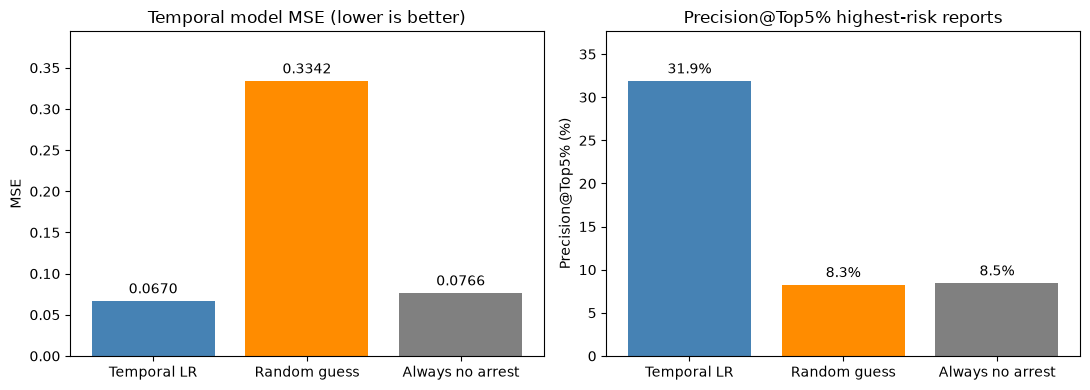

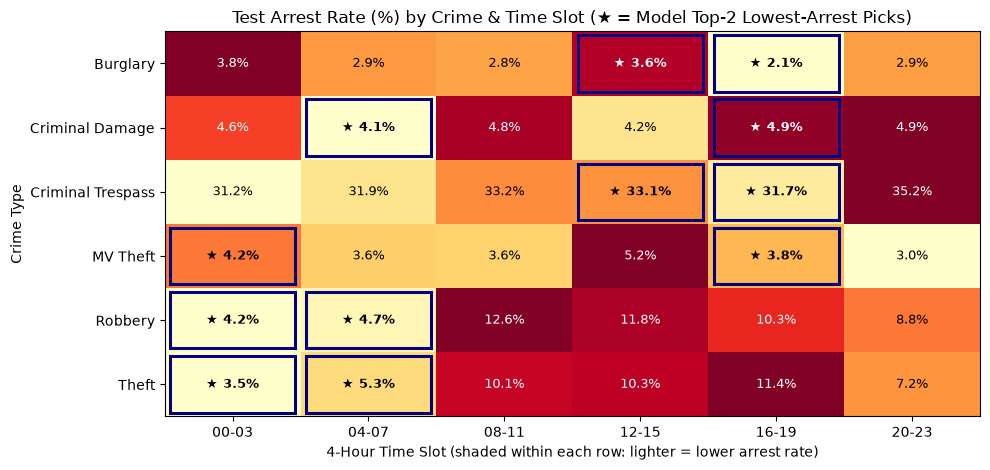

In [9]:
import matplotlib.patches as patches
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import OneHotEncoder

# Use crime_type x time_slot interaction plus day of week and month as temporal inputs.
dates = pd.to_datetime(df["date"])
time_slots = ["00-03", "04-07", "08-11", "12-15", "16-19", "20-23"]
slot = pd.cut(dates.dt.hour, bins=[-1, 3, 7, 11, 15, 19, 23], labels=time_slots).astype(str)
features = pd.DataFrame({
    "crime_slot": df["primary_type"].astype(str) + "_" + slot,
    "day_of_week": dates.dt.day_name(),
    "month": dates.dt.month.astype(str),
})

# Train 80% | Test 20% (chronological split, Old -> New).
split_date = dates.quantile(0.8)
training_rows = dates < split_date
testing_rows = ~training_rows

# Convert category names into numeric input columns.
encoder = OneHotEncoder(handle_unknown="ignore")
X_train = encoder.fit_transform(features.loc[training_rows])
X_test = encoder.transform(features.loc[testing_rows])

# Arrest: 1, No arrest: 0
y_train = df.loc[training_rows, "arrest"].astype(int).to_numpy()
y_test = df.loc[testing_rows, "arrest"].astype(int).to_numpy()

# Fit the model and predict arrest probabilities
temporal_model = LogisticRegression(max_iter=1000)
temporal_model.fit(X_train, y_train)
temporal_probs = temporal_model.predict_proba(X_test)[:, 1]

# Baselines: random probability scores and always predicting 0 ("no arrest").
rng = np.random.default_rng(42)
random_probs = rng.random(len(y_test))
always_no_arrest = np.zeros(len(y_test), dtype=float)

def avg_log_likelihood(y_true, y_prob):
    p = np.clip(y_prob, 1e-15, 1 - 1e-15)
    return float(np.mean(y_true * np.log(p) + (1 - y_true) * np.log(1 - p)))

def precision_at_top_frac(y_true, y_prob, frac=0.05):
    n = max(1, int(frac * len(y_true)))
    top_idx = np.argsort(y_prob)[-n:]
    return float(y_true[top_idx].mean() * 100)

# Evaluate using MSE, RMSE, Average Log-Likelihood, and Precision@Top5%.
models = {
    "Temporal LR": temporal_probs,
    "Random guess": random_probs,
    "Always no arrest": always_no_arrest,
}
metrics = pd.DataFrame({
    name: {
        "MSE": mean_squared_error(y_test, probs),
        "RMSE": np.sqrt(mean_squared_error(y_test, probs)),
        "Avg Log-Likelihood": avg_log_likelihood(y_test, probs),
        "Precision@Top5% (%)": precision_at_top_frac(y_test, probs, frac=0.05),
    }
    for name, probs in models.items()
}).T
print(metrics.round(4).to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
bar_colors = ["steelblue", "darkorange", "gray"]

bars_mse = axes[0].bar(metrics.index, metrics["MSE"], color=bar_colors)
axes[0].bar_label(bars_mse, fmt="%.4f", padding=3)
axes[0].set(title="Temporal model MSE (lower is better)", ylabel="MSE", ylim=(0, metrics["MSE"].max() * 1.18))

bars_prec = axes[1].bar(metrics.index, metrics["Precision@Top5% (%)"], color=bar_colors)
axes[1].bar_label(bars_prec, fmt="%.1f%%", padding=3)
axes[1].set(title="Precision@Top5% highest-risk reports", ylabel="Precision@Top5% (%)", ylim=(0, metrics["Precision@Top5% (%)"].max() * 1.18))

plt.tight_layout()
plt.show()

# Visualize actual test arrest rates by crime & time slot, highlighting the model's Top-2 lowest-arrest picks.
test_eval = pd.DataFrame({
    "primary_type": df.loc[testing_rows, "primary_type"].values,
    "time_slot": slot.loc[testing_rows].values,
    "actual_arrest": y_test,
    "pred_prob": temporal_probs,
})
slot_stats = test_eval.groupby(["primary_type", "time_slot"], as_index=False).mean()
actual_grid = slot_stats.pivot(index="primary_type", columns="time_slot", values="actual_arrest")[time_slots] * 100
pred_grid = slot_stats.pivot(index="primary_type", columns="time_slot", values="pred_prob")[time_slots]
norm_grid = actual_grid.sub(actual_grid.min(axis=1), axis=0).div(actual_grid.max(axis=1) - actual_grid.min(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.imshow(norm_grid.values, cmap="YlOrRd", aspect="auto", vmin=0, vmax=1)
ax.set_xticks(range(len(time_slots)))
ax.set_xticklabels(time_slots)
ax.set_yticks(range(len(actual_grid.index)))
ax.set_yticklabels([c.title().replace("Motor Vehicle Theft", "MV Theft") for c in actual_grid.index])
ax.set(
    title="Test Arrest Rate (%) by Crime & Time Slot (★ = Model Top-2 Lowest-Arrest Picks)",
    xlabel="4-Hour Time Slot (shaded within each row: lighter = lower arrest rate)",
    ylabel="Crime Type",
)

for r, crime in enumerate(actual_grid.index):
    top2_slots = set(pred_grid.loc[crime].nsmallest(2).index)
    for c, ts in enumerate(time_slots):
        val = actual_grid.loc[crime, ts]
        is_pick = ts in top2_slots
        text_color = "white" if norm_grid.loc[crime, ts] > 0.65 else "black"
        label = f"★ {val:.1f}%" if is_pick else f"{val:.1f}%"
        ax.text(c, r, label, ha="center", va="center", color=text_color, fontweight="bold" if is_pick else "normal", fontsize=9.5)
        if is_pick:
            ax.add_patch(patches.Rectangle((c - 0.46, r - 0.44), 0.92, 0.88, linewidth=2.2, edgecolor="navy", facecolor="none"))

plt.tight_layout()
plt.show()

# Expose uniquely-named handles for Model 4 (keeps Model 3's own encoder reachable).
m3_model, m3_encoder = temporal_model, encoder


### Model 4 - Patrol Recommendation (Hybrid "Giga" Model)

Model 4 is the capstone that ties the first three models together. Models 1 and 3 predict **arrest likelihood** (the enforcement value of patrolling a cell), while Model 2 predicts **where crime happens** (crime volume per community area). On their own, none answers the operational question a watch commander faces: *given a limited number of patrols for an upcoming shift, which areas should we send them to?*

Model 4 fuses the two signals into a single target that **no base model produces alone** - the **expected number of arrests** in a cell:

$$\text{expected arrests} \;=\; \underbrace{P(\text{crime occurs})}_{\text{Model 2 volume}} \;\times\; \underbrace{P(\text{arrest}\mid\text{crime})}_{\text{Models 1 and 3}}$$

- **Grid.** One cell = `(community_area, crime_type, month, 4-hour slot, weekend/weekday)`. The units are already shared by the base models: 77 community areas (Models 1 and 2) and the same six 4-hour slots as Models 2B and 3. This gives a 49,896-cell grid over the common window.
- **Per-cell scores (the "contract").** Model 2's `predict_location_risk` supplies `allocated_monthly_crimes`; Model 1 supplies arrest probability averaged over each area-type's incidents (it has no time features); Model 3 supplies arrest probability marginalized over the weekday/weekend days. The three are combined both **unsupervised** (the product above) and with a **learned logistic meta-model** whose standardized coefficients show how much each base model contributes.
- **Leakage control.** All three base models are trained on data before the shared `quantile(0.8)` cutoff (approximately 2026-01-05). Meta-features are built only on the held-out window **2026-02 to 2026-10** (the range Model 2 can forecast), which is split again into **meta-train (Feb to Jul)** and **meta-test (Aug to Oct)**.
- **Evaluation** reuses Model 2's `eval_location` ranking harness (`Top 5 hit`, `Capture@10`, `AUC`) plus **PAI (Predictive Accuracy Index)**, scoring each model on how well it ranks area-shifts by *actual* arrests within each `(month, crime type)` slice. Baselines: historical arrest frequency, each arrest model alone, and crime volume alone.

Model 4 ranking on meta-test (2026-08 to 2026-10, 16,632 cells, 18 (month x type) shift-slices of 924 area-shifts; 2,270 test arrests):
                          Top 5 hit (%)  Capture@10 (%)    AUC  PAI@10
Model                                                                 
Random                            3.422           1.178  0.499   4.267
Hist arrest freq                 46.667           9.396  0.808   8.682
M1 arrest prob only               0.000           0.434  0.645   0.401
M3 arrest prob only               5.556           2.759  0.590   2.549
M2 crime volume only             35.556           8.811  0.820   8.142
Volume x arrest (unsup.)         40.000           9.249  0.829   8.546
Learned meta (3 models)          38.889           8.684  0.824   8.024
Learned meta (+ history)         47.778           9.487  0.830   8.766

Learned logistic meta-model standardized log-odds weights (all positive = each signal adds):
  signal             3 models  + history
  log M2 volume    

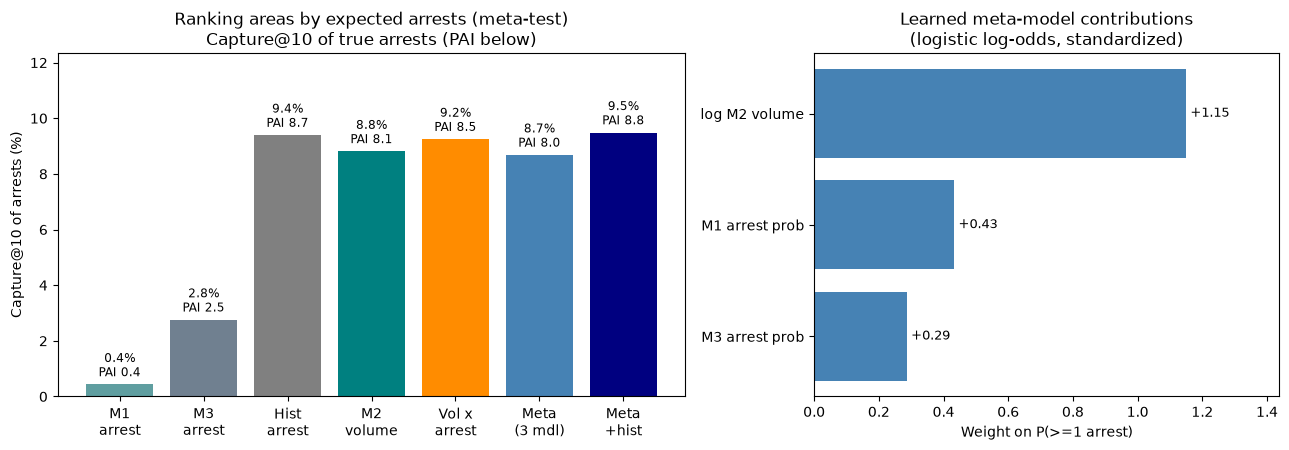

In [10]:
# =====================================================================
# Model 4 - Patrol Recommendation (Hybrid "Giga" Model)
#
# Combine M2's crime-volume forecast (WHERE crime happens) with M1 and
# M3's arrest probability (ENFORCEMENT value) to rank area-shift cells by
# EXPECTED ARRESTS = P(crime) x P(arrest | crime), then recommend the
# top-K to patrol. No single base model produces this target: M2 supplies
# the volume term, M1 and M3 supply the arrest term.
# =====================================================================
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# ---- Grid units are fixed by the base models: community_area (77) x 4h slot. ----
M4_SLOTS = LOC_SLOTS                                   # shared with M2 (2B) and M3
M4_MONTHS = [f"2026-{m:02d}" for m in range(2, 11)]    # clean common window (Feb..Oct 2026)
META_TEST_START = "2026-08"                            # temporal meta-train / meta-test cut
WEEKDAY_DAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]
WEEKEND_DAYS = ["Saturday", "Sunday"]

# M1 and M3 both fit on dates < quantile(0.8); recover that shared base-train cutoff.
all_dates = pd.to_datetime(df["date"])
base_cutoff = all_dates.quantile(0.8)


def slot_of(dt_series):
    return pd.cut(dt_series.dt.hour, bins=[-1, 3, 7, 11, 15, 19, 23], labels=M4_SLOTS).astype(str)


# ---------------------------------------------------------------------
# 1. Base-model per-cell scorers (the contract: a score per query cell)
# ---------------------------------------------------------------------

# M1 - P(arrest | type, location, area). No time features, so it gives one
# score per (area, type): average M1's arrest prob over that cell's
# base-train incidents (leakage-free, keeps the real location-type mix).
base_rows = df.loc[all_dates < base_cutoff]
m1_feat = base_rows[["primary_type", "location_description", "community_area"]].astype(str)
m1_p = m1_model.predict_proba(m1_encoder.transform(m1_feat))[:, 1]
m1_src = pd.DataFrame({
    "ca": pd.to_numeric(base_rows["community_area"], errors="coerce").to_numpy(),
    "primary_type": base_rows["primary_type"].to_numpy(),
    "p": m1_p,
}).dropna(subset=["ca"])
m1_src["ca"] = m1_src["ca"].astype(int)
m1_tab = m1_src.groupby(["ca", "primary_type"])["p"].mean()
m1_type_mean = m1_src.groupby("primary_type")["p"].mean()
m1_global = float(m1_src["p"].mean())

# M3 - P(arrest | type x slot, day_of_week, month). One score per
# (month, type, slot, weekend) by averaging over the group's weekdays.
m3_enum = [
    (ym, int(ym[5:7]), ct, sl, wk, d)
    for ym in M4_MONTHS for ct in CRIME_TYPES for sl in M4_SLOTS
    for wk in (0, 1) for d in (WEEKEND_DAYS if wk else WEEKDAY_DAYS)
]
m3_df = pd.DataFrame(m3_enum, columns=["ym", "mnum", "primary_type", "slot", "weekend", "day_of_week"])
m3_X = pd.DataFrame({
    "crime_slot": m3_df["primary_type"] + "_" + m3_df["slot"],
    "day_of_week": m3_df["day_of_week"],
    "month": m3_df["mnum"].astype(str),
})
m3_df["p"] = m3_model.predict_proba(m3_encoder.transform(m3_X))[:, 1]
m3_tab = m3_df.groupby(["ym", "primary_type", "slot", "weekend"])["p"].mean()

# M2 - crime volume per (area) for each (type, month, slot, weekend) via
# the handoff function; allocated_monthly_crimes already fuses Ridge count
# with the MF shift share.
vol_parts = []
for ym in M4_MONTHS:
    for ct in CRIME_TYPES:
        for sl in M4_SLOTS:
            for wk in (0, 1):
                r = predict_location_risk(ct, ym, time_slot=sl, is_weekend=wk)
                vol_parts.append(pd.DataFrame({
                    "ym": ym, "ca": r["ca"].astype(int).to_numpy(), "primary_type": ct,
                    "slot": sl, "weekend": wk,
                    "crime_volume": r["allocated_monthly_crimes"].to_numpy(),
                }))
grid = pd.concat(vol_parts, ignore_index=True)   # full 49,896-cell grid, 77 areas per slice

# ---------------------------------------------------------------------
# 2. Observed labels: actual crime and arrest counts per cell
# ---------------------------------------------------------------------
obs = loc_df.loc[loc_df["dt"].notna()].copy()
obs["ym"] = obs["dt"].dt.to_period("M").astype(str)
obs["slot"] = slot_of(obs["dt"])
obs["weekend"] = (obs["dt"].dt.day_of_week >= 5).astype(int)
obs["arr"] = obs["arrest"].astype(int)
obs_win = obs.loc[obs["ym"].isin(M4_MONTHS)]
labels = (
    obs_win.groupby(["ym", "ca", "primary_type", "slot", "weekend"])
    .agg(crime_count=("arr", "size"), arrest_count=("arr", "sum")).reset_index()
)
grid = grid.merge(labels, on=["ym", "ca", "primary_type", "slot", "weekend"], how="left")
grid[["crime_count", "arrest_count"]] = grid[["crime_count", "arrest_count"]].fillna(0.0)

# Attach base-model scores to every grid cell.
mi1 = pd.MultiIndex.from_arrays([grid["ca"], grid["primary_type"]])
grid["m1_arrest"] = m1_tab.reindex(mi1).to_numpy()
fill1 = grid["primary_type"].map(m1_type_mean).fillna(m1_global).to_numpy()
grid["m1_arrest"] = np.where(np.isnan(grid["m1_arrest"]), fill1, grid["m1_arrest"])

mi3 = pd.MultiIndex.from_arrays([grid["ym"], grid["primary_type"], grid["slot"], grid["weekend"]])
grid["m3_arrest"] = m3_tab.reindex(mi3).to_numpy()

# Historical arrest frequency per cell (monthly rate from data strictly
# before the meta-test window) - a strong baseline and a meta feature.
hist = obs.loc[obs["ym"] < META_TEST_START]
n_hist_months = hist["ym"].nunique()
hist_rate = hist.groupby(["ca", "primary_type", "slot", "weekend"])["arr"].sum() / n_hist_months
mih = pd.MultiIndex.from_arrays([grid["ca"], grid["primary_type"], grid["slot"], grid["weekend"]])
grid["hist_arrest_freq"] = hist_rate.reindex(mih).fillna(0.0).to_numpy()

# Unsupervised "giga" score: expected arrests = volume x blended arrest prob.
grid["arrest_prob"] = 0.5 * (grid["m1_arrest"] + grid["m3_arrest"])
grid["exp_arrests"] = grid["crime_volume"] * grid["arrest_prob"]

# ---------------------------------------------------------------------
# 3. Learned meta-model: how much does each base model contribute?
# ---------------------------------------------------------------------
# Logistic regression on "cell had >=1 arrest", standardized inputs, so
# the coefficients read as each signal's log-odds contribution. The
# headline model stacks the THREE base-model outputs; a second variant
# also ingests raw history. L2 regularization keeps weights positive
# despite volume/history collinearity (plain linear regression did not).
train_mask = (grid["ym"] < META_TEST_START).to_numpy()
test_mask = ~train_mask
y = grid["arrest_count"].to_numpy(float)
ybin = (y >= 1).astype(int)


def fit_meta(cols, log_cols):
    X = grid[cols].to_numpy(float).copy()
    for j in log_cols:                              # heavy-tailed -> log1p
        X[:, j] = np.log1p(X[:, j])
    sc = StandardScaler().fit(X[train_mask])
    Xs = sc.transform(X)
    m = LogisticRegression(max_iter=1000).fit(Xs[train_mask], ybin[train_mask])
    return m, m.predict_proba(Xs)[:, 1]


feat_cols = ["crime_volume", "m1_arrest", "m3_arrest"]
feat_labels = ["log M2 volume", "M1 arrest prob", "M3 arrest prob"]
meta, grid["meta_score"] = fit_meta(feat_cols, [0])
meta_full, grid["meta_full_score"] = fit_meta(feat_cols + ["hist_arrest_freq"], [0, 3])
meta_coef, meta_full_coef = meta.coef_[0], meta_full.coef_[0]

# ---------------------------------------------------------------------
# 4. Evaluation on the held-out meta-test months (reuse M2's harness + PAI)
# ---------------------------------------------------------------------
def pai_at_k(counts, score, groups, k=10):
    vals = []
    for _, g in pd.DataFrame({"g": groups, "c": counts, "s": score}).groupby("g", sort=False):
        c, s = g["c"].to_numpy(float), g["s"].to_numpy(float)
        if c.sum() <= 0:
            continue
        cap = c[np.argsort(-s)[:k]].sum() / c.sum()
        vals.append(cap / (k / len(c)))
    return float(np.mean(vals))


te_grid = grid.loc[test_mask].copy()
te_keys_m4 = (te_grid["ym"] + "|" + te_grid["primary_type"]).to_numpy()
arr = te_grid["arrest_count"].to_numpy()
candidates = [
    ("Random", np.zeros(len(te_grid)), 25),
    ("Hist arrest freq", te_grid["hist_arrest_freq"].to_numpy(), 1),
    ("M1 arrest prob only", te_grid["m1_arrest"].to_numpy(), 1),
    ("M3 arrest prob only", te_grid["m3_arrest"].to_numpy(), 1),
    ("M2 crime volume only", te_grid["crime_volume"].to_numpy(), 1),
    ("Volume x arrest (unsup.)", te_grid["exp_arrests"].to_numpy(), 1),
    ("Learned meta (3 models)", te_grid["meta_score"].to_numpy(), 1),
    ("Learned meta (+ history)", te_grid["meta_full_score"].to_numpy(), 1),
]
m4_rows = []
for name, score, n_rand in candidates:
    res, _ = eval_location(arr, score, arr, te_keys_m4, inc_reg=False, inc_rank=True, n_rand=n_rand)
    m4_rows.append({
        "Model": name, "Top 5 hit (%)": res["Top 5 hit (%)"],
        "Capture@10 (%)": res["Capture@10 (%)"], "AUC": res["AUC"],
        "PAI@10": pai_at_k(arr, score, te_keys_m4, 10),
    })
m4_metrics = pd.DataFrame(m4_rows).set_index("Model")

n_groups = len(np.unique(te_keys_m4))
print(
    f"Model 4 ranking on meta-test ({te_grid['ym'].min()} to {te_grid['ym'].max()}, "
    f"{len(te_grid):,} cells, {n_groups} (month x type) shift-slices of 924 area-shifts; "
    f"{int(arr.sum()):,} test arrests):"
)
print(m4_metrics.round(3).to_string())
print("\nLearned logistic meta-model standardized log-odds weights (all positive = each signal adds):")
print(f"  {'signal':<16}{'3 models':>11}{'+ history':>11}")
for k, lbl in enumerate(feat_labels):
    print(f"  {lbl:<16}{meta_coef[k]:>+11.3f}{meta_full_coef[k]:>+11.3f}")
print(f"  {'hist arrest freq':<16}{'':>11}{meta_full_coef[3]:>+11.3f}")

# ---------------------------------------------------------------------
# 5. Example deployable recommendation: busiest != most arrests
# ---------------------------------------------------------------------
EX_MONTH, EX_SLOT, EX_WKND = "2026-10", "20-23", 1
ex = grid.loc[(grid["ym"] == EX_MONTH) & (grid["slot"] == EX_SLOT) & (grid["weekend"] == EX_WKND)]
rec = ex.groupby("ca").agg(
    crime_volume=("crime_volume", "sum"), exp_arrests=("exp_arrests", "sum")
).reset_index()
rec["area"] = rec["ca"].map(lambda c: CA_NAMES.get(int(c), f"Area {int(c)}"))
rec["vol_rank"] = rec["crime_volume"].rank(ascending=False, method="min").astype(int)
rec["arr_rank"] = rec["exp_arrests"].rank(ascending=False, method="min").astype(int)
print(f"\nExample patrol slice ({EX_MONTH}, weekend {EX_SLOT}, all crime types pooled):")
print("  Top 5 areas by CRIME VOLUME:")
print(rec.sort_values("crime_volume", ascending=False)
      .head(5)[["area", "crime_volume", "exp_arrests", "arr_rank"]].round(2).to_string(index=False))
print("  Top 5 areas by EXPECTED ARRESTS (Model 4 patrol recommendation):")
print(rec.sort_values("exp_arrests", ascending=False)
      .head(5)[["area", "exp_arrests", "crime_volume", "vol_rank"]].round(2).to_string(index=False))

# ---------------------------------------------------------------------
# 6. Plots: model comparison (left) and each model's learned weight (right)
# ---------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.35, 1]})
plot_models = [
    "M1 arrest prob only", "M3 arrest prob only", "Hist arrest freq", "M2 crime volume only",
    "Volume x arrest (unsup.)", "Learned meta (3 models)", "Learned meta (+ history)",
]
short = ["M1\narrest", "M3\narrest", "Hist\narrest", "M2\nvolume",
         "Vol x\narrest", "Meta\n(3 mdl)", "Meta\n+hist"]
pm = m4_metrics.loc[plot_models]
colors = ["cadetblue", "slategray", "gray", "teal", "darkorange", "steelblue", "navy"]
b = axes[0].bar(short, pm["Capture@10 (%)"], color=colors)
axes[0].bar_label(
    b, labels=[f"{c:.1f}%\nPAI {p:.1f}" for c, p in zip(pm["Capture@10 (%)"], pm["PAI@10"])],
    padding=3, fontsize=8.5,
)
axes[0].set(
    title="Ranking areas by expected arrests (meta-test)\nCapture@10 of true arrests (PAI below)",
    ylabel="Capture@10 of arrests (%)", ylim=(0, pm["Capture@10 (%)"].max() * 1.3),
)

co_order = np.argsort(meta_coef)            # ascending, so largest ends on top of barh
bc = axes[1].barh([feat_labels[i] for i in co_order], [meta_coef[i] for i in co_order], color="steelblue")
axes[1].bar_label(bc, fmt="%+.2f", padding=3, fontsize=9)
axes[1].axvline(0, color="black", lw=0.7)
axes[1].set(
    title="Learned meta-model contributions\n(logistic log-odds, standardized)",
    xlabel="Weight on P(>=1 arrest)", xlim=(0, max(meta_coef) * 1.25),
)
plt.tight_layout()
plt.show()

**Takeaways from Model 4:** Adding arrest probability to crime volume helps. The unsupervised **Volume x arrest** product beats **crime volume alone** on every ranking metric (`Capture@10` `8.8% -> 9.2%`, `AUC` `0.820 -> 0.829`, `PAI` `8.1 -> 8.5`), confirming that the busiest area is not always where the most arrests happen: for the weekend `20-23` shift in `2026-10`, **The Loop** jumps from #5 by volume to #2 by expected arrests, while higher-volume `Area 24` drops out of the top 5. Notably, no learned *linear* combiner beat this hand-specified product on the precision metrics, because arrests really are a *product* (volume x rate), not a sum - the inductive bias matters.

The learned **logistic meta-model** gives all three base models **positive** standardized log-odds weight (`log volume +1.15` > `M1 +0.43` > `M3 +0.29`), so each contributes, with crime volume dominant. **Historical arrest frequency** is the single hardest baseline to beat (`Capture@10` `9.4%`), consistent with the predictive-policing literature - but the **full meta-model** that stacks the three model signals *with* history edges ahead of it on every metric (`Capture@10` `9.5%`, `AUC` `0.830`, `PAI` `8.8`) while keeping every coefficient positive, i.e. the model signals still add information beyond raw history.

**Fairness caveat** (cf. Lum and Isaac, 2016, *"To predict and serve?"*): ranking by *arrests* optimizes enforcement yield and therefore inherits any bias in who gets arrested. Model 2's crime-occurrence ranking is the fairer deployment target; Model 4's arrest ranking is best read as an *enforcement-efficiency* layer on top of it.